# 2. Comparar modelos con tu dataset limpio
Entrada: V0.1/LICIT_depurando_sinNulos.feather. Se comparan regresión logística,
árbol de decisión, red neuronal MLP y Random Forest. No se utilizan CSV mensuales.

**Limitación:** el archivo no permite agrupar por licitación ni validar en el tiempo.
Separar vectores idénticos por grupos reduce una contaminación concreta, pero
distintas filas de una misma licitación todavía podrían estar en conjuntos diferentes.
No interpretes las métricas como una prueba de rendimiento en licitaciones futuras.

In [1]:
from pathlib import Path
import os
BASE = Path.cwd().resolve()
if not (BASE / "02_Comparacion_de_Modelos.ipynb").exists() and (BASE / "V0.2" / "02_Comparacion_de_Modelos.ipynb").exists():
    BASE = BASE / "V0.2"
if not (BASE / "02_Comparacion_de_Modelos.ipynb").exists():
    raise FileNotFoundError("Abre el proyecto desde la raíz o desde V0.2.")
os.chdir(BASE)
import pandas as pd
import numpy as np
import json
import joblib
import matplotlib.pyplot as plt
from IPython.display import display
FUENTE = BASE.parent / "V0.1" / "LICIT_depurando_sinNulos.feather"
SALIDA = BASE / "resultados_dataset_limpio"
SALIDA.mkdir(exist_ok=True)
print("Dataset de entrada:", FUENTE)

Dataset de entrada: D:\Licit\1\ML-SmartBids\V0.1\LICIT_depurando_sinNulos.feather


## 2.1. Datos, configuración y procedencia
Para controlar tiempo, cada modelo se ajusta con hasta 120.000 filas de TRAIN,
seleccionando grupos completos con semilla fija. Calibración, validación y test
conservan sus registros. MAX_FILAS_TRAIN=None usa todo TRAIN.
La configuración y las huellas de datos/código controlan la reutilización.

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve,
    brier_score_loss, log_loss)
from pathlib import Path
import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
EXCLUIR = ["NumeroOferentes", "CantidadReclamos", "DuracionProceso"]
CODIGOS = ["CodigoUnidad", "CodigoProductoONU"]

# Funciones auxiliares incluidas aquí: no se requieren módulos .py del proyecto.
def catalogo(incluir_random_forest=False):
    """Mismos tres algoritmos del trabajo original, sin ofertas sintéticas."""
    modelos = {
        "Regresion_Logistica": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
        "Arbol_Decision": DecisionTreeClassifier(max_depth=10, min_samples_leaf=50,
                                                class_weight="balanced", random_state=42),
        "Red_Neuronal_MLP": MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=100,
                                          early_stopping=True, n_iter_no_change=8,
                                          random_state=42),
    }
    if incluir_random_forest:
        modelos["Random_Forest"] = RandomForestClassifier(
            n_estimators=100, max_depth=14, min_samples_leaf=30,
            class_weight="balanced_subsample", random_state=42, n_jobs=2)
    return modelos

def metricas(y, p, umbral):
    pred = p >= umbral
    return {"F1": float(f1_score(y, pred, zero_division=0)),
            "precision": float(precision_score(y, pred, zero_division=0)),
            "recall": float(recall_score(y, pred, zero_division=0)),
            "ROC_AUC": float(roc_auc_score(y, p)),
            "average_precision": float(average_precision_score(y, p)),
            "Brier": float(brier_score_loss(y, p)),
            "log_loss": float(log_loss(y, p)),
            "matriz_confusion_orden_0_1": confusion_matrix(y, pred, labels=[0, 1]).tolist()}

def umbral_f1(y, p):
    precision, recall, thresholds = precision_recall_curve(y, p)
    den = precision[:-1] + recall[:-1]
    f1 = np.divide(2 * precision[:-1] * recall[:-1], den, out=np.zeros_like(den), where=den > 0)
    return float(thresholds[int(np.argmax(f1))])

In [3]:
def preparar_limpio(ruta):
    """Verifica el dataset del usuario; no repite su cadena de depuración."""
    df = pd.read_feather(ruta)
    requeridas = ["Seleccionada", "Valor Total Ofertado", "Cantidad Ofertada", "Cantidad"]
    faltan = sorted(set(requeridas) - set(df.columns))
    if faltan:
        raise ValueError(f"Faltan columnas en el Feather limpio: {faltan}")
    antes = len(df)
    valido = df.Seleccionada.isin([0, 1])
    valido &= df[["Valor Total Ofertado", "Cantidad Ofertada", "Cantidad"]].gt(0).all(axis=1)
    df = df.loc[valido].copy().reset_index(drop=True)
    y = df.pop("Seleccionada").astype("int8")
    X = df.drop(columns=EXCLUIR, errors="ignore")
    # Los montos ya están transformados por V0.1. No se reconvierten monedas.
    # No asumimos que el presupuesto global es un presupuesto por ítem.
    for columna in ["MontoEstimado", "Valor Total Ofertado", "Cantidad", "Cantidad Ofertada"]:
        if columna in X:
            X[columna] = np.log1p(X[columna].clip(lower=0))
    for columna in CODIGOS:
        if columna in X:
            X[columna] = X[columna].astype("string").fillna("sin_codigo").astype(str)
    numericas = X.select_dtypes(include="number").columns
    X[numericas] = X[numericas].replace([np.inf, -np.inf], np.nan)
    # La huella NO incluye el objetivo: vectores idénticos se mantienen juntos
    # aunque sus etiquetas sean diferentes. No representa una licitación real.
    grupos = pd.util.hash_pandas_object(X, index=False).to_numpy()
    auditoria = {"archivo": str(Path(ruta).resolve()), "filas_entrada": antes,
                 "filas_utilizadas": len(X), "filas_excluidas": antes-len(X),
                 "motivo_exclusion": "Objetivo inválido o monto/cantidad de oferta no positivo",
                 "predictores": X.columns.tolist(), "excluidas_por_disponibilidad": EXCLUIR,
                 "limitacion": "Sin identificador de licitación ni fechas exactas; no se verifica generalización temporal por licitación.",
                 "grupos": "Huella de predictores, no ID de licitación",
                 "transformacion": "log1p en montos y cantidades; códigos como categorías"}
    return X, y, grupos, auditoria

def dividir_grupos(indices, grupos, fraccion, semilla):
    splitter = GroupShuffleSplit(n_splits=1, test_size=fraccion, random_state=semilla)
    a, b = next(splitter.split(indices, groups=grupos[indices]))
    return indices[a], indices[b]

def separar_limpio(y, grupos):
    indices = np.arange(len(y))
    desarrollo, test = dividir_grupos(indices, grupos, .15, 42)
    desarrollo, validacion = dividir_grupos(desarrollo, grupos, .15/.85, 43)
    train, calibracion = dividir_grupos(desarrollo, grupos, .15/.70, 44)
    partes = dict(train=train, calibracion=calibracion, validacion=validacion, test=test)
    vistos = set()
    for nombre, idx in partes.items():
        actuales = set(grupos[idx])
        if vistos & actuales:
            raise AssertionError("Se compartieron predictores idénticos entre conjuntos.")
        vistos |= actuales
        if set(y.iloc[idx]) != {0, 1}:
            raise ValueError(f"{nombre} debe contener ambas clases.")
    return partes

In [4]:
import hashlib
MAX_FILAS_TRAIN = 120_000
REENTRENAR = False
X, y, grupos, auditoria = preparar_limpio(FUENTE)
partes = separar_limpio(y, grupos)
with FUENTE.open("rb") as f:
    huella = hashlib.file_digest(f, "sha256").hexdigest()
config = {"dataset": huella, "codigo": hashlib.sha256("".join("".join(c["source"]) for c in json.loads((BASE/"02_Comparacion_de_Modelos.ipynb").read_text(encoding="utf-8"))["cells"] if c["cell_type"] == "code").encode("utf-8")).hexdigest(),
          "max_filas_train": MAX_FILAS_TRAIN}
control = SALIDA / "configuracion.json"
necesarios = ["modelo_dataset_limpio.joblib", "cv.json", "validacion.json", "probabilidades_test.npy", "prueba_registros.csv"]
hay = all((SALIDA / n).exists() for n in necesarios) and control.exists()
EJECUTAR = REENTRENAR or not hay or json.loads(control.read_text(encoding="utf-8")) != config
display(pd.DataFrame({k: {"filas": len(v), "seleccionadas_pct": y.iloc[v].mean()*100}
                      for k,v in partes.items()}).T)
print("Entrenar:", EJECUTAR)

,filas,seleccionadas_pct
train,1158990.0,17.017403
calibracion,315803.0,16.914659
validacion,315785.0,16.924490
test,315036.0,16.843472


Entrenar: False


## 2.2. Pipeline y muestra de entrenamiento
Se conservan las columnas one-hot existentes. Imputación, escala y categorías
de códigos se aprenden solamente en el subconjunto de ajuste. Los grupos se
crean sin usar Seleccionada: vectores iguales con objetivos diferentes quedan juntos.
La separación principal tiene aproximadamente 55/15/15/15 por grupos, sin estratificar;
se comprueba que cada conjunto contenga ambas clases y se muestran sus proporciones.

In [5]:
def pipeline_limpio(X, modelo):
    categorias = [c for c in CODIGOS if c in X]
    numeros = [c for c in X if c not in categorias]
    prep = ColumnTransformer([
        ("numeros", Pipeline([("imputar", SimpleImputer(strategy="median")),
                               ("escalar", StandardScaler())]), numeros),
        ("codigos", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10,
                                  max_categories=150), categorias),
    ])
    return Pipeline([("preprocesar", prep), ("modelo", modelo)])

def limitar_indices(indices, grupos, limite):
    if limite is None or len(indices) <= limite:
        return indices
    # Selección reproducible de grupos enteros, compartida por los algoritmos.
    tamanos = pd.Series(grupos[indices]).value_counts().sample(frac=1, random_state=42)
    elegidos, total = [], 0
    for grupo, cantidad in tamanos.items():
        if total + cantidad <= limite:
            elegidos.append(grupo)
            total += cantidad
    salida = indices[np.isin(grupos[indices], elegidos)]
    if not len(salida):
        raise ValueError("El límite de entrenamiento no admite ningún grupo completo.")
    return salida

def ajustar_limpio(X, y, grupos, fit, cal, modelo, limite):
    fit = limitar_indices(fit, grupos, limite)
    inicio = time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        base = pipeline_limpio(X, modelo).fit(X.iloc[fit], y.iloc[fit])
    calibrado = CalibratedClassifierCV(FrozenEstimator(base), method="sigmoid")
    calibrado.fit(X.iloc[cal], y.iloc[cal])
    return calibrado, {"filas_ajuste": len(fit), "segundos": time.perf_counter()-inicio,
                        "advertencias": [str(a.message) for a in avisos]}

## 2.3. Validación cruzada de los cuatro algoritmos
Se usan tres folds de GroupKFold dentro de TRAIN. Cada fold reserva calibración
interna independiente. Esta CV es por vectores idénticos, no temporal ni por licitación.
F1 se mide con umbral 0,5 en CV; el umbral final se elegirá después en validación.
Logística y árbol usan pesos de clase; Random Forest pesos en sus muestras;
MLP usa sus ejemplos sin balanceo y parada temprana interna dentro de TRAIN.

In [6]:
def cv_limpio(X, y, grupos, train, limite=120_000):
    resultados = []
    cv = GroupKFold(n_splits=3, shuffle=True, random_state=42)
    for fold, (fit_local, val_local) in enumerate(cv.split(train, y.iloc[train], grupos[train]), start=1):
        fit, cal = dividir_grupos(train[fit_local], grupos, .2, 42)
        val = train[val_local]
        for nombre, modelo in catalogo(True).items():
            print(f"CV {fold}: {nombre}", flush=True)
            calibrado, detalle = ajustar_limpio(X, y, grupos, fit, cal, modelo, limite)
            p = calibrado.predict_proba(X.iloc[val])[:, 1]
            resultados.append({"modelo": nombre, "fold": fold, **metricas(y.iloc[val], p, .5), **detalle})
    return pd.DataFrame(resultados)

In [7]:
if EJECUTAR:
    cv = cv_limpio(X, y, grupos, partes["train"], MAX_FILAS_TRAIN)
    cv.to_json(SALIDA / "cv.json", orient="records", indent=2)
else:
    cv = pd.read_json(SALIDA / "cv.json")
metricas_comparar = ["precision", "recall", "F1", "ROC_AUC", "average_precision", "Brier"]
resumen = cv.groupby("modelo")[metricas_comparar].agg(["mean", "std"])
display(resumen.round(4))

precision          recall              F1         ROC_AUC  \
                         mean     std    mean     std    mean     std    mean   
modelo                                                                          
Arbol_Decision         0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.6245   
Random_Forest          0.7676  0.0447  0.0042  0.0016  0.0083  0.0032  0.6387   
Red_Neuronal_MLP       0.5141  0.0189  0.0293  0.0036  0.0554  0.0064  0.6475   
Regresion_Logistica    0.2589  0.0666  0.0005  0.0002  0.0009  0.0003  0.6261   

                            average_precision           Brier          
                        std              mean     std    mean     std  
modelo                                                                 
Arbol_Decision       0.0047            0.2495  0.0081  0.1371  0.0008  
Random_Forest        0.0027            0.2679  0.0057  0.1360  0.0007  
Red_Neuronal_MLP     0.0030            0.2783  0.0034  0.1355  0.0008  
Regresion_Logistica  0.0011            0.2520  0.0036  0.1370  0.0008

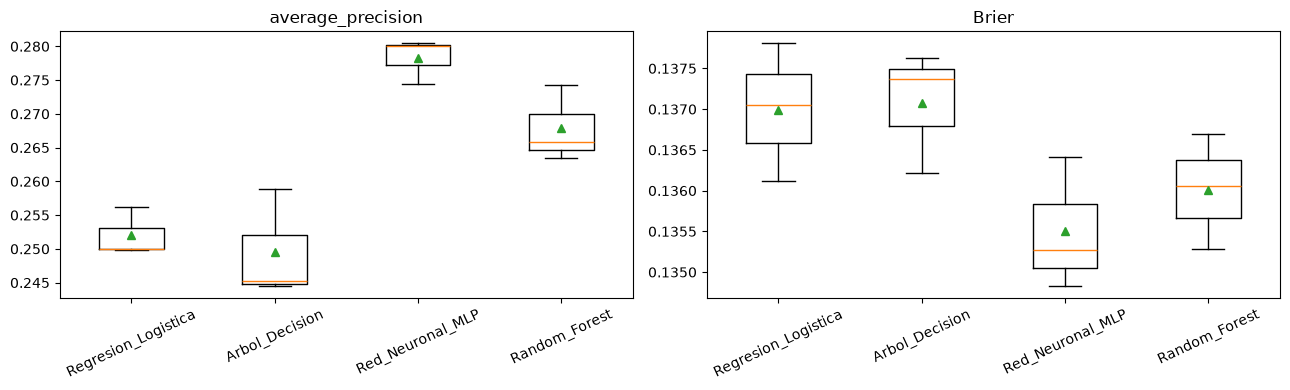

In [8]:
nombres = list(cv.modelo.unique())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metrica in zip(axes, ["average_precision", "Brier"]):
    ax.boxplot([cv.loc[cv.modelo.eq(n), metrica] for n in nombres], tick_labels=nombres, showmeans=True)
    ax.set_title(metrica)
    ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()

## 2.4. Ajuste final y comparación en validación
Todos se entrenan con la misma muestra, se calibran con otro conjunto y se
selecciona el de menor Brier en VALIDACIÓN. El umbral de cada modelo se ajusta
por F1 en ese conjunto. Test no participa en esta elección.

In [9]:
def validar_limpio(X, y, grupos, partes, limite=120_000):
    entrenados, resultados = {}, []
    for nombre, modelo in catalogo(True).items():
        print(f"Ajuste final: {nombre}", flush=True)
        calibrado, detalle = ajustar_limpio(X, y, grupos, partes["train"], partes["calibracion"], modelo, limite)
        val = partes["validacion"]
        p = calibrado.predict_proba(X.iloc[val])[:, 1]
        umbral = umbral_f1(y.iloc[val], p)
        resultados.append({"modelo": nombre, "umbral": umbral, **metricas(y.iloc[val], p, umbral), **detalle})
        entrenados[nombre] = calibrado
    return entrenados, pd.DataFrame(resultados).sort_values("Brier").reset_index(drop=True)

In [10]:
if EJECUTAR:
    entrenados, tabla = validar_limpio(X, y, grupos, partes, MAX_FILAS_TRAIN)
    tabla.to_json(SALIDA / "validacion.json", orient="records", indent=2)
else:
    tabla = pd.read_json(SALIDA / "validacion.json")
display(tabla[["modelo", "umbral", *metricas_comparar, "filas_ajuste", "segundos"]])
display(tabla[["modelo", "advertencias"]])

,modelo,umbral,precision,recall,F1,ROC_AUC,average_precision,Brier,filas_ajuste,segundos
0,Red_Neuronal_MLP,0.154084,0.235686,0.624717,0.342251,0.648675,0.273208,0.135200,120000,14.395916
1,Random_Forest,0.158747,0.224740,0.633287,0.331749,0.635201,0.260800,0.135766,120000,10.661483
2,Regresion_Logistica,0.163899,0.215693,0.665731,0.325821,0.624272,0.246758,0.136604,120000,2.930419
3,Arbol_Decision,0.154107,0.213380,0.721695,0.329375,0.625153,0.241601,0.136657,120000,3.740437


,modelo,advertencias
0,Red_Neuronal_MLP,[]
1,Random_Forest,[]
2,Regresion_Logistica,[]
3,Arbol_Decision,[]


## 2.5. Prueba del ganador
Solo se evalúa en test el candidato seleccionado. Se compara contra una probabilidad
constante basada en TRAIN, se guarda el modelo y se exportan diez registros de
ejemplo con su resultado real. El histórico de 2024 ya fue analizado previamente:
esto es una comparación exploratoria, no una nueva confirmación independiente.

In [11]:
def probar_limpio(X, y, partes, entrenados, tabla, auditoria, salida):
    ganador = tabla.iloc[0]
    nombre, umbral = ganador["modelo"], float(ganador["umbral"])
    modelo = entrenados[nombre]
    test = partes["test"]
    p = modelo.predict_proba(X.iloc[test])[:, 1]
    dummy = DummyClassifier(strategy="prior").fit(X.iloc[partes["train"]], y.iloc[partes["train"]])
    referencia = dummy.predict_proba(X.iloc[test])[:, 1]
    observada, predicha = calibration_curve(y.iloc[test], p, n_bins=10, strategy="quantile")
    informe = {"modelo": nombre, "umbral": umbral, "test": metricas(y.iloc[test], p, umbral),
               "referencia": metricas(y.iloc[test], referencia, .5), "auditoria": auditoria,
               "calibracion": {"predicha": predicha.tolist(), "observada": observada.tolist()},
               "particiones": {k: {"filas": len(v), "tasa_seleccion": float(y.iloc[v].mean())} for k, v in partes.items()},
               "nota": "Evaluación exploratoria sobre datos de 2024 ya analizados; no valida licitaciones futuras ni garantiza separación por licitación."}
    salida = Path(salida)
    salida.mkdir(exist_ok=True, parents=True)
    artefacto = {"modelo": modelo, "umbral": umbral, "columnas": X.columns.tolist(),
                 "informe": informe, "entrada": "Predictores transformados de LICIT_depurando_sinNulos.feather, no CSV de oferta sin preparar"}
    joblib.dump(artefacto, salida / "modelo_dataset_limpio.joblib")
    ejemplo = X.iloc[test[:10]].copy()
    ejemplo["Seleccionada_real"] = y.iloc[test[:10]].to_numpy()
    ejemplo["probabilidad_seleccion"] = p[:10]
    ejemplo["prediccion"] = (p[:10] >= umbral).astype(int)
    ejemplo.to_csv(salida / "prueba_registros.csv", index=False, encoding="utf-8-sig")
    np.save(salida / "probabilidades_test.npy", p)
    return artefacto, p

In [12]:
if EJECUTAR:
    artefacto, p_test = probar_limpio(X, y, partes, entrenados, tabla, auditoria, SALIDA)
    control.write_text(json.dumps(config, indent=2), encoding="utf-8")
else:
    artefacto = joblib.load(SALIDA / "modelo_dataset_limpio.joblib")
    p_test = np.load(SALIDA / "probabilidades_test.npy")
informe = artefacto["informe"]
print("Seleccionado:", informe["modelo"])
display(pd.DataFrame({"modelo": informe["test"], "referencia": informe["referencia"]})
          .drop(index="matriz_confusion_orden_0_1"))
print(informe["nota"])

Seleccionado: Red_Neuronal_MLP


,modelo,referencia
F1,0.336817,0.0
precision,0.231706,0.0
recall,0.616475,0.0
ROC_AUC,0.646633,0.5
average_precision,0.27129,0.168435
Brier,0.134782,0.140067
log_loss,0.435428,0.453406


Evaluación exploratoria sobre datos de 2024 ya analizados; no valida licitaciones futuras ni garantiza separación por licitación.


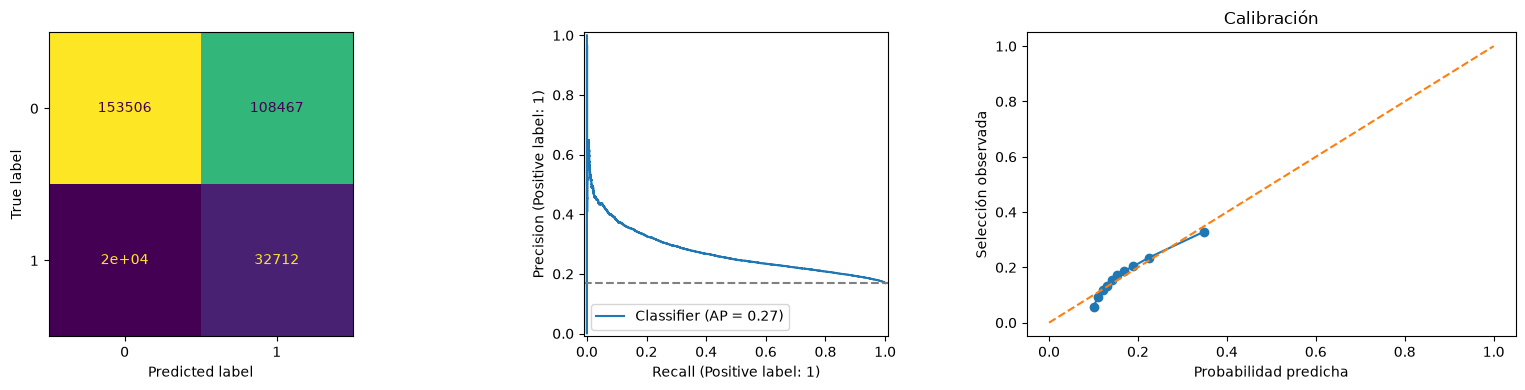

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay
y_test = y.iloc[partes["test"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(y_test, p_test >= artefacto["umbral"], ax=axes[0], colorbar=False)
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=axes[1])
axes[1].axhline(y_test.mean(), linestyle="--", color="gray")
cal = pd.DataFrame(informe["calibracion"])
axes[2].plot(cal.predicha, cal.observada, marker="o")
axes[2].plot([0,1], [0,1], linestyle="--")
axes[2].set(xlabel="Probabilidad predicha", ylabel="Selección observada", title="Calibración")
fig.tight_layout()
plt.show()